# Mobile-Former on the Chest CT-Scan Images Dataset (Kaggle)

Implementation of **Mobile-Former: Bridging MobileNet and Transformer** (Chen et al., CVPR 2022) in PyTorch, trained to classify 2D chest CT slices into **4 classes**: adenocarcinoma, large cell carcinoma, squamous cell carcinoma, normal.

Dataset: [Chest CT-Scan images Dataset, Kaggle (mohamedhanyyy)](https://www.kaggle.com/datasets/mohamedhanyyy/chest-ctscan-images)

Outputs: train / val / test loss curves, accuracy, macro F1 / precision / recall curves, confusion matrices, classification report, ROC curves.

> Use a GPU runtime. In Colab you need a Kaggle API token (see the download cell). In a Kaggle notebook, just add the dataset via *Add Input*.

In [1]:
!pip install -q kagglehub seaborn scikit-learn

## 1. Download the dataset

**Option A (Kaggle notebook):** add the dataset as input; it appears under `/kaggle/input/`.

**Option B (Colab / local):** `kagglehub` needs your Kaggle credentials. Create a token at kaggle.com -> Settings -> API, then either upload `kaggle.json` to `~/.kaggle/` or set `KAGGLE_USERNAME` / `KAGGLE_KEY` below.

In [2]:
import os, glob
# os.environ["KAGGLE_USERNAME"] = "your_username"   # <- only if not using kaggle.json
# os.environ["KAGGLE_KEY"]      = "your_key"

if os.path.exists("/kaggle/input"):                       # running inside Kaggle
    root = "/kaggle/input"
else:
    import kagglehub
    root = kagglehub.dataset_download("mohamedhanyyy/chest-ctscan-images")
print("downloaded to:", root)

# locate the folder that contains train/ valid/ test/
DATA_DIR = None
for dp, dn, _ in os.walk(root):
    if {"train", "valid", "test"} <= set(dn):
        DATA_DIR = dp; break
assert DATA_DIR, "could not find train/valid/test folders"
print("DATA_DIR:", DATA_DIR)
for s in ["train", "valid", "test"]:
    print(s, {d: len(os.listdir(os.path.join(DATA_DIR, s, d))) for d in sorted(os.listdir(os.path.join(DATA_DIR, s)))})

downloaded to: /kaggle/input
DATA_DIR: /kaggle/input/datasets/mohamedhanyyy/chest-ctscan-images/Data
train {'adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib': 195, 'large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa': 115, 'normal': 148, 'squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa': 155}
valid {'adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib': 23, 'large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa': 21, 'normal': 13, 'squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa': 15}
test {'adenocarcinoma': 120, 'large.cell.carcinoma': 51, 'normal': 54, 'squamous.cell.carcinoma': 90}


## 2. Config and data

In [3]:
import numpy as np, torch, torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# ---------------- hyper-parameters ----------------
IMG_SIZE     = 224
BATCH_SIZE   = 32
EPOCHS       = 50
LR           = 1e-3
WEIGHT_DECAY = 0.05
WIDTH_MULT   = 0.5      # 1.0 = full Mobile-Former-294M widths (Table 1)
NUM_TOKENS   = 6        # M: number of global tokens in Former
TOKEN_DIM    = 128      # d: token dimension (paper: 192)
SEED         = 42
NUM_WORKERS  = 2

# ---------------- switches (all OFF = plain training) ----------------
USE_AUGMENTATION  = False   # random affine + brightness/contrast on training images
USE_CLASS_WEIGHTS = False   # class-weighted cross-entropy
LABEL_SMOOTHING   = 0.0     # e.g. 0.05 to enable

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

CLASS_NAMES = ["adenocarcinoma", "large.cell.carcinoma", "normal", "squamous.cell.carcinoma"]

def class_index(folder_name):
    """Folder names differ between splits (train/valid use long names, test uses short ones)."""
    for i, n in enumerate(CLASS_NAMES):
        if folder_name.lower().startswith(n):
            return i
    raise ValueError(folder_name)

class CTFolder(Dataset):
    def __init__(self, split, tf):
        self.tf, self.items = tf, []
        base = os.path.join(DATA_DIR, split)
        for d in sorted(os.listdir(base)):
            for f in sorted(os.listdir(os.path.join(base, d))):
                if f.lower().endswith((".png", ".jpg", ".jpeg")):
                    self.items.append((os.path.join(base, d, f), class_index(d)))
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        path, y = self.items[i]
        img = Image.open(path).convert("L")          # grayscale, 1 channel
        return self.tf(img), y

eval_tf = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)),
                              transforms.ToTensor(), transforms.Normalize([0.5], [0.5])])
if USE_AUGMENTATION:
    train_tf = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05)),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.ToTensor(), transforms.Normalize([0.5], [0.5]),
    ])
else:                  # plain: resize + normalise only, same as val/test
    train_tf = eval_tf

train_ds, val_ds, test_ds = CTFolder("train", train_tf), CTFolder("valid", eval_tf), CTFolder("test", eval_tf)
print({k: len(v) for k, v in dict(train=train_ds, val=val_ds, test=test_ds).items()})

train_labels = np.array([y for _, y in train_ds.items])
counts = np.bincount(train_labels, minlength=4)
print(dict(zip(CLASS_NAMES, counts)))

device: cuda
{'train': 613, 'val': 72, 'test': 315}
{'adenocarcinoma': np.int64(195), 'large.cell.carcinoma': np.int64(115), 'normal': np.int64(148), 'squamous.cell.carcinoma': np.int64(155)}


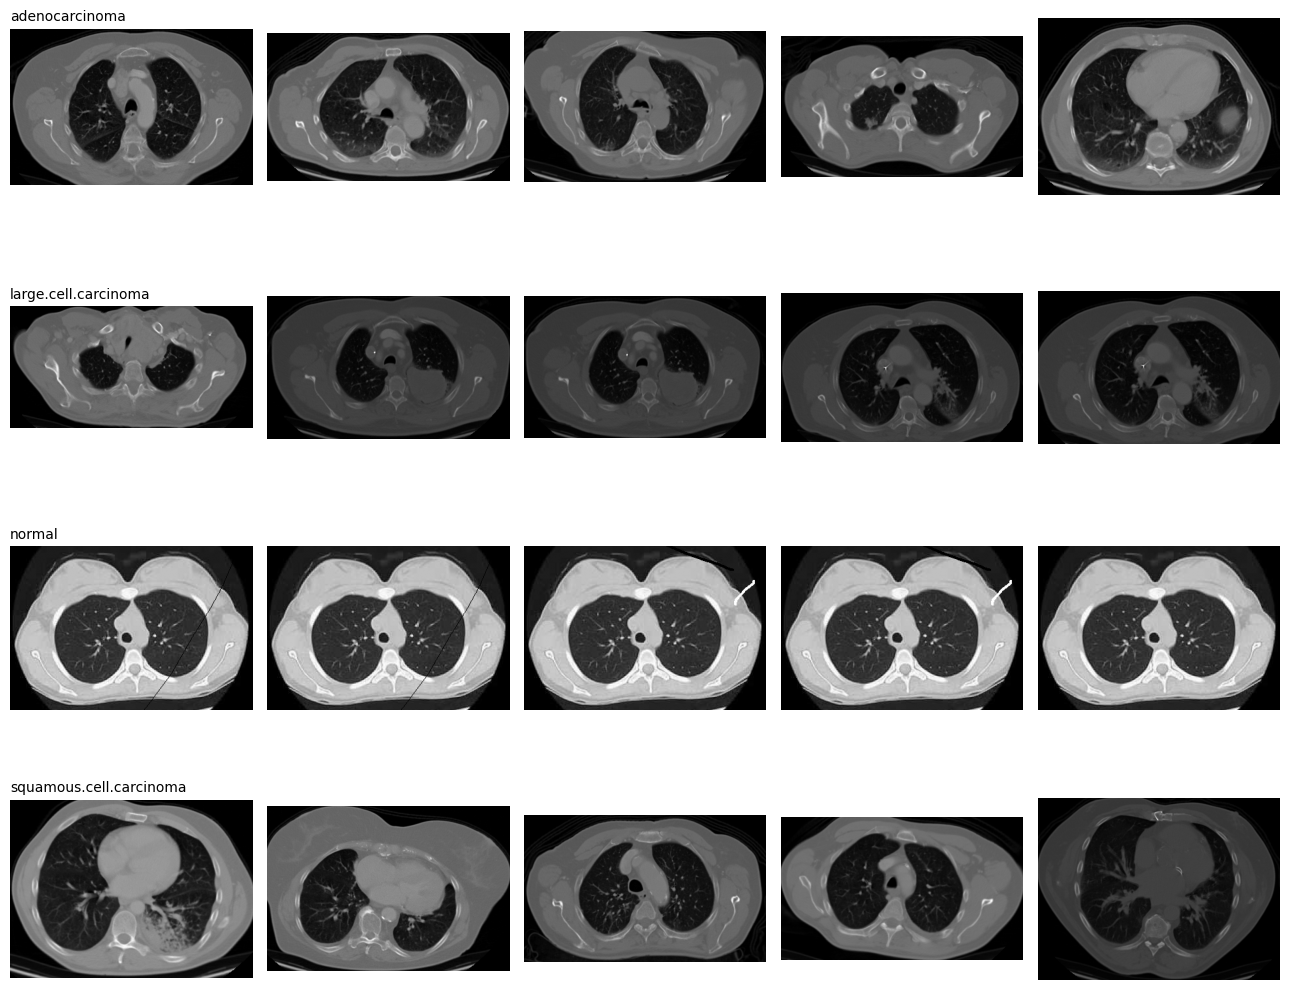

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(4, 5, figsize=(13, 11))
for cls in range(4):
    idx = np.where(train_labels == cls)[0][:5]
    for a, i in zip(ax[cls], idx):
        a.imshow(Image.open(train_ds.items[i][0]).convert("L"), cmap="gray"); a.axis("off")
    ax[cls][0].set_title(CLASS_NAMES[cls], loc="left", fontsize=10)
plt.tight_layout(); plt.show()

In [5]:
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True, drop_last=True, generator=g)
val_loader   = DataLoader(val_ds,   64, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_ds,  64, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

class_weights = torch.tensor(counts.sum() / (len(counts) * counts), dtype=torch.float32).to(device) if USE_CLASS_WEIGHTS else None
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=LABEL_SMOOTHING)
print("class weights:", None if class_weights is None else class_weights.cpu().numpy().round(3))

class weights: None


## 3. Mobile-Former model

| Module | Implementation |
|---|---|
| **Mobile** sub-block | Inverted bottleneck (1x1 -> 3x3 depthwise -> 1x1) with **dynamic ReLU**; its parameters are generated from Former's first output token |
| **Former** sub-block | Learnable tokens, multi-head self-attention + FFN (expansion 2), post-LayerNorm |
| **Mobile -> Former** | Light-weight cross attention (Eq. 1): query `z W^Q`, key/value = raw local features, then `W^O` |
| **Mobile <- Former** | Light-weight cross attention (Eq. 2): query = raw local features, key/value `z W^K`, `z W^V` |
| Head | Global avg-pool, concat with first token, 2 FC layers with h-swish |

Stage layout follows Table 1. The paper's supplementary material wasn't available, so details like the downsample block are my reconstruction. Width and token dimension are reduced by default because the dataset is small (~600 training images).

In [6]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


def make_divisible(v, divisor=8, min_value=8):
    new_v = max(min_value, int(v + divisor / 2) // divisor * divisor)
    if new_v < 0.9 * v:
        new_v += divisor
    return new_v


class HSwish(nn.Module):
    def forward(self, x):
        return x * F.relu6(x + 3.0) / 6.0


# ---------------------------------------------------------------
# Dynamic ReLU (spatial-shared). Parameters come from Former's first token.
#   y_c = max_k ( a_k,c * x_c + b_k,c ),  k = 1, 2
# ---------------------------------------------------------------
class DyReLU(nn.Module):
    def __init__(self, channels, k=2, lambda_a=1.0, lambda_b=0.5):
        super().__init__()
        self.channels, self.k = channels, k
        self.lambda_a, self.lambda_b = lambda_a * 2.0, lambda_b
        # initial slopes: a1 = 1, a2 = 0 -> behaves like ReLU at init
        self.register_buffer("init_a", torch.tensor([1.0] + [0.0] * (k - 1)))
        self.register_buffer("init_b", torch.zeros(k))

    @property
    def n_params(self):
        return 2 * self.k * self.channels

    def forward(self, x, theta):
        # theta: (B, 2*k*C) raw output of the theta MLP
        B, C = theta.shape[0], self.channels
        t = 2.0 * torch.sigmoid(theta) - 1.0               # in (-1, 1)
        t = t.view(B, C, 2 * self.k)
        a = (t[..., : self.k] - 0.5) * self.lambda_a + self.init_a   # (B, C, k)
        b = t[..., self.k:] * self.lambda_b + self.init_b            # (B, C, k)
        a = a.view(B, C, self.k, 1, 1)
        b = b.view(B, C, self.k, 1, 1)
        out = x.unsqueeze(2) * a + b                       # (B, C, k, H, W)
        return out.max(dim=2)[0]


# ---------------------------------------------------------------
# Mobile sub-block: inverted bottleneck with dynamic ReLU (Fig. 3)
# ---------------------------------------------------------------
class MobileBlock(nn.Module):
    def __init__(self, inp, exp, oup, stride, token_dim, k=2):
        super().__init__()
        self.use_res = (stride == 1 and inp == oup)
        self.pw1 = nn.Conv2d(inp, exp, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(exp)
        self.act1 = DyReLU(exp, k)
        self.dw = nn.Conv2d(exp, exp, 3, stride, 1, groups=exp, bias=False)
        self.bn2 = nn.BatchNorm2d(exp)
        self.act2 = DyReLU(exp, k)
        self.pw2 = nn.Conv2d(exp, oup, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(oup)
        # theta: two MLP layers on the first global token -> parameters for both DyReLUs
        n = self.act1.n_params + self.act2.n_params
        self.theta = nn.Sequential(
            nn.Linear(token_dim, token_dim // 4), nn.ReLU(inplace=True),
            nn.Linear(token_dim // 4, n))
        self.n1 = self.act1.n_params

    def forward(self, x, z1):
        th = self.theta(z1)
        th1, th2 = th[:, : self.n1], th[:, self.n1:]
        out = self.act1(self.bn1(self.pw1(x)), th1)
        out = self.act2(self.bn2(self.dw(out)), th2)
        out = self.bn3(self.pw2(out))
        return x + out if self.use_res else out


# ---------------------------------------------------------------
# Mobile -> Former : light-weight cross attention (Eq. 1)
#   Query = z W^Q (Former side), Key = Value = x (NO projections on Mobile side)
#   heads concatenated, then W^O maps C -> d
# ---------------------------------------------------------------
class Mobile2Former(nn.Module):
    def __init__(self, C, d, heads=2):
        super().__init__()
        assert C % heads == 0
        self.h, self.C = heads, C
        self.q = nn.Linear(d, C)          # W^Q  (per-head matrices stacked)
        self.o = nn.Linear(C, d)          # W^O
        self.scale = (C // heads) ** -0.5

    def forward(self, x, z):
        B, C, H, W = x.shape
        M = z.shape[1]
        q = self.q(z).view(B, M, self.h, C // self.h).transpose(1, 2)           # B,h,M,C/h
        kv = x.flatten(2).transpose(1, 2).reshape(B, H * W, self.h, C // self.h).transpose(1, 2)  # B,h,HW,C/h
        attn = (q @ kv.transpose(-1, -2)) * self.scale                          # B,h,M,HW
        attn = attn.softmax(-1)
        out = (attn @ kv).transpose(1, 2).reshape(B, M, C)                      # B,M,C
        return self.o(out)


# ---------------------------------------------------------------
# Mobile <- Former : light-weight cross attention (Eq. 2)
#   Query = x (NO projection), Key = z W^K, Value = z W^V
# ---------------------------------------------------------------
class Former2Mobile(nn.Module):
    def __init__(self, C, d, heads=2):
        super().__init__()
        assert C % heads == 0
        self.h, self.C = heads, C
        self.k = nn.Linear(d, C)          # W^K
        self.v = nn.Linear(d, C)          # W^V
        self.scale = (C // heads) ** -0.5
        self.last_attn = None

    def forward(self, x, z):
        B, C, H, W = x.shape
        M = z.shape[1]
        q = x.flatten(2).transpose(1, 2).reshape(B, H * W, self.h, C // self.h).transpose(1, 2)  # B,h,HW,C/h
        k = self.k(z).view(B, M, self.h, C // self.h).transpose(1, 2)           # B,h,M,C/h
        v = self.v(z).view(B, M, self.h, C // self.h).transpose(1, 2)
        attn = ((q @ k.transpose(-1, -2)) * self.scale).softmax(-1)             # B,h,HW,M
        self.last_attn = attn.detach()
        out = (attn @ v).transpose(1, 2).reshape(B, H * W, C)                   # B,HW,C
        return out.transpose(1, 2).reshape(B, C, H, W)


# ---------------------------------------------------------------
# Former sub-block: standard transformer block (MHA + FFN, expansion 2, post-LN)
# ---------------------------------------------------------------
class FormerBlock(nn.Module):
    def __init__(self, d, heads=4, ffn_ratio=2, dropout=0.0):
        super().__init__()
        self.attn = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.ln1 = nn.LayerNorm(d)
        self.ffn = nn.Sequential(nn.Linear(d, d * ffn_ratio), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(d * ffn_ratio, d))
        self.ln2 = nn.LayerNorm(d)

    def forward(self, z):
        z = self.ln1(z + self.attn(z, z, z, need_weights=False)[0])
        z = self.ln2(z + self.ffn(z))
        return z


# ---------------------------------------------------------------
# One Mobile-Former block = Mobile->Former, Former, Mobile, Mobile<-Former
# For the downsample variant (stride 2) the bridge Mobile->Former sees an
# average-pooled copy of x to keep the cost low.
# ---------------------------------------------------------------
class MobileFormerBlock(nn.Module):
    def __init__(self, inp, exp, oup, stride, d, heads_bridge=2, heads_former=4, dropout=0.0):
        super().__init__()
        self.stride = stride
        self.m2f = Mobile2Former(inp, d, heads_bridge)
        self.ln_m2f = nn.LayerNorm(d)
        self.former = FormerBlock(d, heads_former, 2, dropout)
        self.mobile = MobileBlock(inp, exp, oup, stride, d)
        self.f2m = Former2Mobile(oup, d, heads_bridge)

    def forward(self, x, z):
        x_in = F.avg_pool2d(x, 2) if self.stride == 2 else x
        z = self.ln_m2f(z + self.m2f(x_in, z))     # Mobile -> Former
        z = self.former(z)                         # Former
        x = self.mobile(x, z[:, 0])                # Mobile (DyReLU params from first token)
        x = x + self.f2m(x, z)                     # Mobile <- Former
        return x, z


# ---------------------------------------------------------------
# Full network
# ---------------------------------------------------------------
class MobileFormer(nn.Module):
    """
    Mobile-Former following Table 1 (294M model) of the paper.
    width_mult scales all channel counts, num_tokens/token_dim set the Former.
    """
    # (exp, out, stride)   -- from Table 1, stages 2-5
    CFG = [
        (96, 24, 2), (96, 24, 1),
        (144, 48, 2), (192, 48, 1),
        (288, 96, 2), (384, 96, 1), (576, 128, 1), (768, 128, 1),
        (768, 192, 2), (1152, 192, 1), (1152, 192, 1),
    ]

    def __init__(self, in_chans=1, num_classes=2, width_mult=0.5, num_tokens=6,
                 token_dim=128, head_dim=512, dropout=0.2, former_dropout=0.0):
        super().__init__()
        w = lambda c: make_divisible(c * width_mult)
        self.num_tokens, self.token_dim = num_tokens, token_dim

        # learnable, randomly initialised global tokens
        self.tokens = nn.Parameter(torch.randn(num_tokens, token_dim) * 0.02)

        stem_c = w(16)
        self.stem = nn.Sequential(nn.Conv2d(in_chans, stem_c, 3, 2, 1, bias=False),
                                  nn.BatchNorm2d(stem_c), HSwish())
        # lite bottleneck: 3x3 depthwise (expands x2) + pointwise squeeze
        self.bneck = nn.Sequential(
            nn.Conv2d(stem_c, stem_c * 2, 3, 1, 1, groups=stem_c, bias=False),
            nn.BatchNorm2d(stem_c * 2), nn.ReLU(inplace=True),
            nn.Conv2d(stem_c * 2, stem_c, 1, bias=False), nn.BatchNorm2d(stem_c))

        blocks, inp = [], stem_c
        for exp, out, s in self.CFG:
            blocks.append(MobileFormerBlock(inp, w(exp), w(out), s, token_dim,
                                            dropout=former_dropout))
            inp = w(out)
        self.blocks = nn.ModuleList(blocks)

        last_c = w(1152)
        self.last = nn.Sequential(nn.Conv2d(inp, last_c, 1, bias=False),
                                  nn.BatchNorm2d(last_c), HSwish())
        self.head = nn.Sequential(
            nn.Linear(last_c + token_dim, head_dim), HSwish(),
            nn.Dropout(dropout), nn.Linear(head_dim, num_classes))
        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(m.weight, mode="fan_out")
        elif isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, x):
        B = x.shape[0]
        z = self.tokens.unsqueeze(0).expand(B, -1, -1)
        x = self.stem(x)
        x = x + self.bneck(x)
        for blk in self.blocks:
            x, z = blk(x, z)
        x = self.last(x).mean((2, 3))               # global average pooling
        feat = torch.cat([x, z[:, 0]], dim=1)       # concat with first global token
        return self.head(feat)

In [7]:
model = MobileFormer(in_chans=1, num_classes=4, width_mult=WIDTH_MULT,
                     num_tokens=NUM_TOKENS, token_dim=TOKEN_DIM).to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters())/1e6:.2f} M")

x = torch.randn(2, 1, IMG_SIZE, IMG_SIZE, device=device)
print("output shape:", model(x).shape)
try:
    from torch.utils.flop_counter import FlopCounterMode
    model.eval()
    with FlopCounterMode(display=False) as fc:
        model(x[:1])
    print(f"Approx. MAdds per image: {fc.get_total_flops()/2/1e6:.1f} M @ {IMG_SIZE}x{IMG_SIZE}")
except Exception as e:
    print("FLOP counter unavailable:", e)

Parameters: 3.39 M
output shape: torch.Size([2, 4])
Approx. MAdds per image: 90.9 M @ 224x224


## 4. Training

AdamW, warm-up + cosine decay, plain cross-entropy (no class weights, no label smoothing, no augmentation by default), mixed precision on GPU. Test metrics are logged each epoch **only** to draw the test curves; the best checkpoint is picked by **validation macro-F1**.

In [8]:
import math, time, copy, random, numpy as np, torch, torch.nn as nn
from sklearn.metrics import precision_recall_fscore_support, accuracy_score


def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    tot_loss, n = 0.0, 0
    ys, ps, probs = [], [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss = criterion(out, y)
        tot_loss += loss.item() * x.size(0); n += x.size(0)
        ys.append(y.cpu()); ps.append(out.argmax(1).cpu()); probs.append(out.softmax(1).cpu())
    return tot_loss / n, torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(probs).numpy()


def metrics(y, p):
    """Macro-averaged precision / recall / F1 over all classes."""
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
    return dict(acc=accuracy_score(y, p), precision=pr, recall=rc, f1=f1)


def train_epoch(model, loader, criterion, optimizer, scaler, device, use_amp):
    model.train()
    tot_loss, n = 0.0, 0
    ys, ps = [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            out = model(x)
        loss = criterion(out.float(), y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scaler.step(optimizer); scaler.update()
        tot_loss += loss.item() * x.size(0); n += x.size(0)
        ys.append(y.cpu()); ps.append(out.argmax(1).detach().cpu())
    return tot_loss / n, torch.cat(ys).numpy(), torch.cat(ps).numpy()


def fit(model, train_loader, val_loader, test_loader, criterion, device,
        epochs=50, lr=1e-3, weight_decay=0.05, warmup=3, use_amp=True, ckpt="best_mobileformer_ct.pt"):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda e: (e + 1) / warmup if e < warmup
        else 0.5 * (1 + math.cos(math.pi * (e - warmup) / max(1, epochs - warmup))))
    use_amp = use_amp and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    keys = ["loss", "acc", "f1", "precision", "recall"]
    hist = {f"{s}_{k}": [] for s in ["train", "val", "test"] for k in keys}
    hist["lr"] = []
    best_f1, best_state = -1, None
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tl, ty, tp = train_epoch(model, train_loader, criterion, optimizer, scaler, device, use_amp)
        vl, vy, vp, _ = evaluate(model, val_loader, criterion, device)
        sl, sy, sp, _ = evaluate(model, test_loader, criterion, device)   # monitoring only
        for name, loss, y, p in [("train", tl, ty, tp), ("val", vl, vy, vp), ("test", sl, sy, sp)]:
            hist[f"{name}_loss"].append(loss)
            for k, v in metrics(y, p).items():
                hist[f"{name}_{k}"].append(v)
        hist["lr"].append(optimizer.param_groups[0]["lr"])
        sched.step()
        improved = hist["val_f1"][-1] > best_f1
        if improved:   # model selection uses VALIDATION only, never the test set
            best_f1 = hist["val_f1"][-1]
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, ckpt)
        print(f"Ep {ep:02d}/{epochs} | {time.time()-t0:5.1f}s | "
              f"loss tr {tl:.4f} val {vl:.4f} test {sl:.4f} | "
              f"macro-F1 tr {hist['train_f1'][-1]:.3f} val {hist['val_f1'][-1]:.3f} test {hist['test_f1'][-1]:.3f}"
              + ("  *best*" if improved else ""))
    model.load_state_dict(best_state)
    return hist

In [9]:
set_seed(SEED)
model = MobileFormer(in_chans=1, num_classes=4, width_mult=WIDTH_MULT,
                     num_tokens=NUM_TOKENS, token_dim=TOKEN_DIM).to(device)
history = fit(model, train_loader, val_loader, test_loader, criterion, device,
              epochs=EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY)

Ep 01/50 |  45.3s | loss tr 1.0025 val 1.7429 test 1.6261 | macro-F1 tr 0.483 val 0.175 test 0.135  *best*
Ep 02/50 |   4.9s | loss tr 0.8623 val 2.0620 test 1.7434 | macro-F1 tr 0.567 val 0.124 test 0.185
Ep 03/50 |   5.1s | loss tr 0.9364 val 1.6352 test 1.5737 | macro-F1 tr 0.526 val 0.246 test 0.333  *best*
Ep 04/50 |   5.2s | loss tr 0.8338 val 1.4213 test 1.2082 | macro-F1 tr 0.586 val 0.342 test 0.390  *best*
Ep 05/50 |   5.1s | loss tr 0.8343 val 1.2627 test 2.2259 | macro-F1 tr 0.564 val 0.451 test 0.399  *best*
Ep 06/50 |   5.0s | loss tr 0.7328 val 1.5648 test 1.2042 | macro-F1 tr 0.634 val 0.339 test 0.584
Ep 07/50 |   5.0s | loss tr 0.7825 val 1.2923 test 3.0176 | macro-F1 tr 0.603 val 0.427 test 0.386
Ep 08/50 |   5.0s | loss tr 0.7653 val 1.3971 test 2.1177 | macro-F1 tr 0.628 val 0.406 test 0.411
Ep 09/50 |   5.2s | loss tr 0.7543 val 1.2122 test 2.2257 | macro-F1 tr 0.604 val 0.525 test 0.331  *best*
Ep 10/50 |   5.0s | loss tr 0.7427 val 1.1616 test 0.9645 | macro-F1 

## 5. Training curves

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize

def plot_history(h):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(2, 3, figsize=(18, 9)); ax = ax.ravel()
    for a, (key, title) in zip(ax, [("loss", "Loss"), ("acc", "Accuracy"), ("f1", "Macro F1"),
                                    ("precision", "Macro precision"), ("recall", "Macro recall")]):
        for split, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
            a.plot(ep, h[f"{split}_{key}"], label=split, color=c, lw=2)
        a.set_title(title); a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
    ax[5].plot(ep, h["lr"], color="tab:red", lw=2); ax[5].set_title("Learning rate")
    ax[5].set_xlabel("epoch"); ax[5].grid(alpha=.3)
    plt.tight_layout(); plt.savefig("training_curves.png", dpi=150); plt.show()

def plot_loss_only(h):
    ep = range(1, len(h["train_loss"]) + 1)
    plt.figure(figsize=(8, 5))
    for split, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
        plt.plot(ep, h[f"{split}_loss"], label=f"{split} loss", color=c, lw=2)
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Train / Val / Test loss")
    plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.savefig("loss_curves.png", dpi=150); plt.show()

def plot_confusion(y, p, names, title, fname):
    cm = confusion_matrix(y, p, labels=range(len(names)))
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    fig, ax = plt.subplots(1, 2, figsize=(15, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names, ax=ax[0])
    ax[0].set_title(f"{title} - counts")
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", xticklabels=names, yticklabels=names, ax=ax[1], vmin=0, vmax=1)
    ax[1].set_title(f"{title} - normalised by true class")
    for a in ax:
        a.set_xlabel("Predicted"); a.set_ylabel("True"); a.tick_params(axis="x", rotation=30)
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

def plot_roc(y, prob, names, title="ROC curves (test, one-vs-rest)"):
    yb = label_binarize(y, classes=range(len(names)))
    plt.figure(figsize=(6.5, 5.5))
    for i, n in enumerate(names):
        fpr, tpr, _ = roc_curve(yb[:, i], prob[:, i])
        plt.plot(fpr, tpr, lw=2, label=f"{n} (AUC {auc(fpr, tpr):.3f})")
    plt.plot([0, 1], [0, 1], "k--", alpha=.5)
    plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title(title)
    plt.legend(loc="lower right", fontsize=8); plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig("roc_curves.png", dpi=150); plt.show()
    return roc_auc_score(y, prob, multi_class="ovr", average="macro")

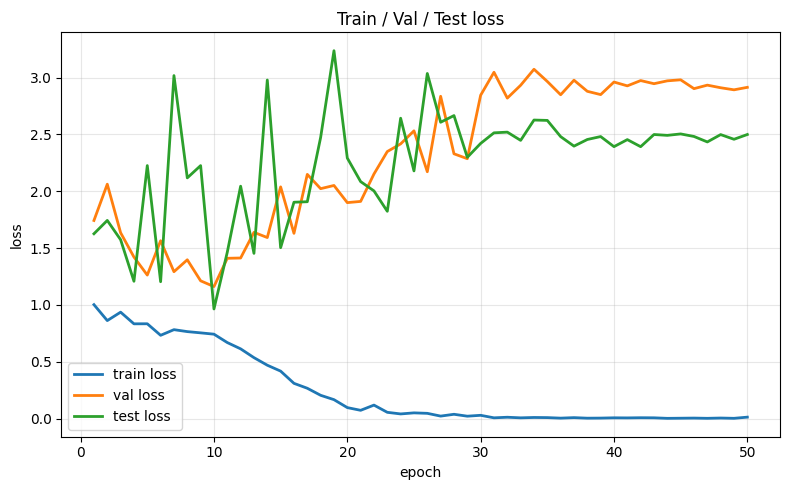

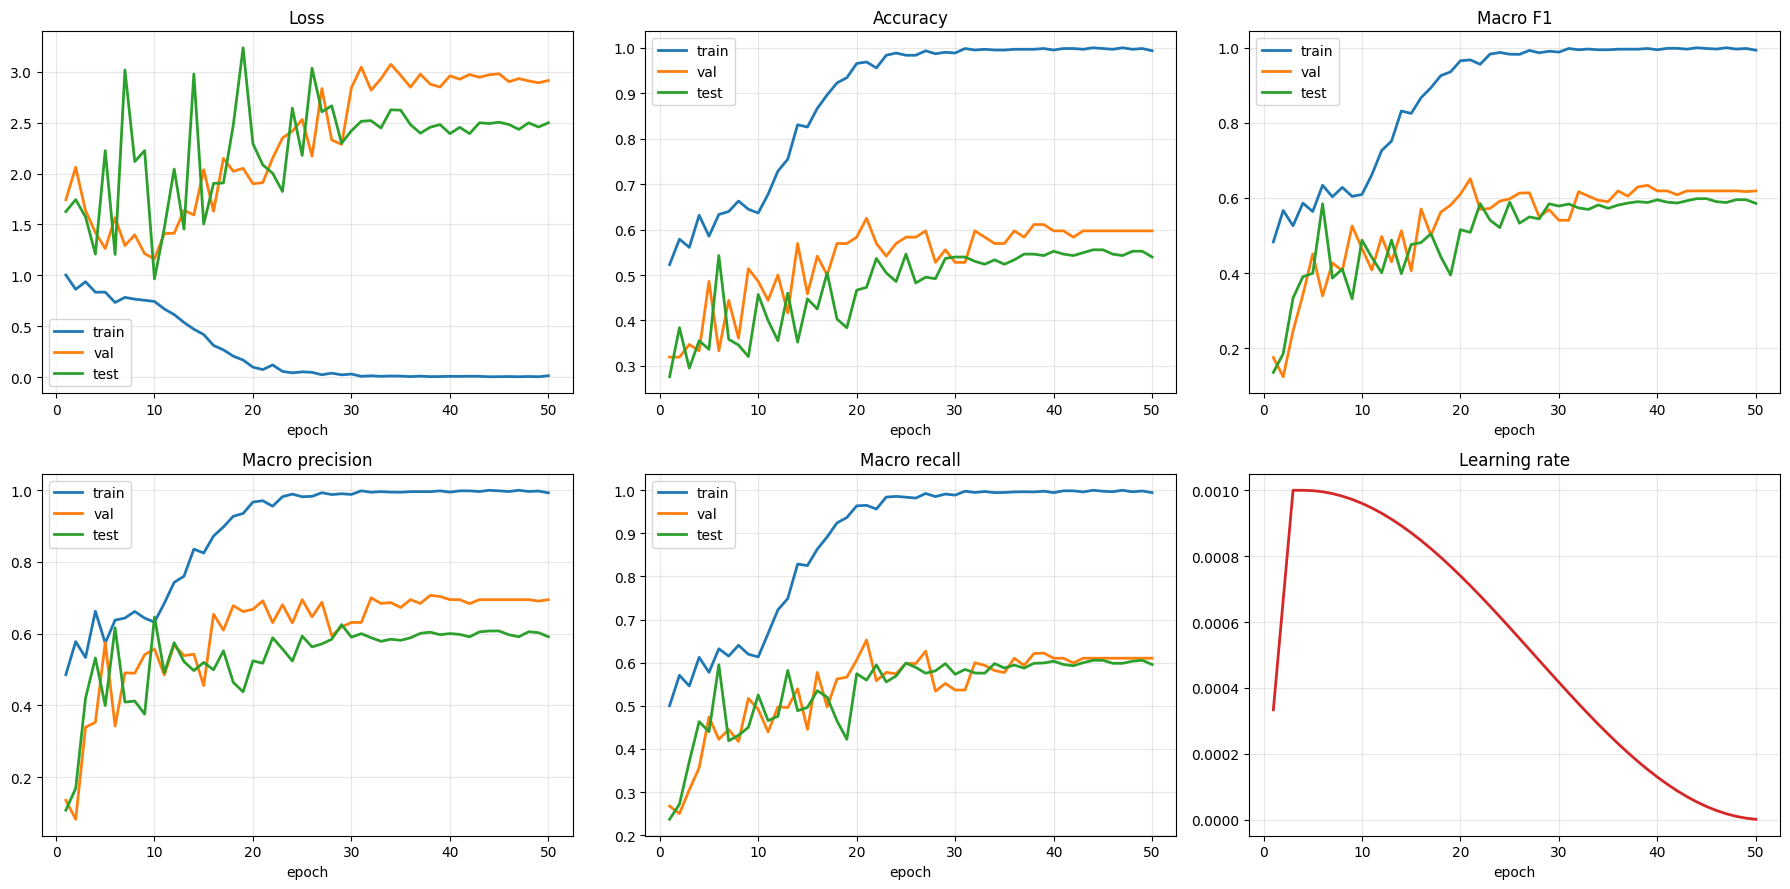

In [11]:
plot_loss_only(history)
plot_history(history)

## 6. Final evaluation (best-validation checkpoint)

In [12]:
import pandas as pd
results = {}
for name, loader in [("val", val_loader), ("test", test_loader)]:
    results[name] = evaluate(model, loader, criterion, device)

rows = []
for name, (loss, y, p, prob) in results.items():
    m = metrics(y, p); m["loss"] = loss
    m["auc_ovr"] = roc_auc_score(y, prob, multi_class="ovr", average="macro")
    rows.append(pd.Series(m, name=name))
print(pd.DataFrame(rows)[["loss", "acc", "precision", "recall", "f1", "auc_ovr"]].round(4))

_, ytest, ptest, probtest = results["test"]
print("\nTest classification report")
print(classification_report(ytest, ptest, target_names=CLASS_NAMES, digits=4, zero_division=0))

        loss    acc  precision  recall      f1  auc_ovr
val   1.9107  0.625     0.6917  0.6527  0.6510   0.8039
test  2.0849  0.473     0.5175  0.5597  0.5082   0.7780

Test classification report
                         precision    recall  f1-score   support

         adenocarcinoma     0.3158    0.1000    0.1519       120
   large.cell.carcinoma     0.2710    0.5686    0.3671        51
                 normal     1.0000    0.9259    0.9615        54
squamous.cell.carcinoma     0.4833    0.6444    0.5524        90

               accuracy                         0.4730       315
              macro avg     0.5175    0.5597    0.5082       315
           weighted avg     0.4737    0.4730    0.4400       315



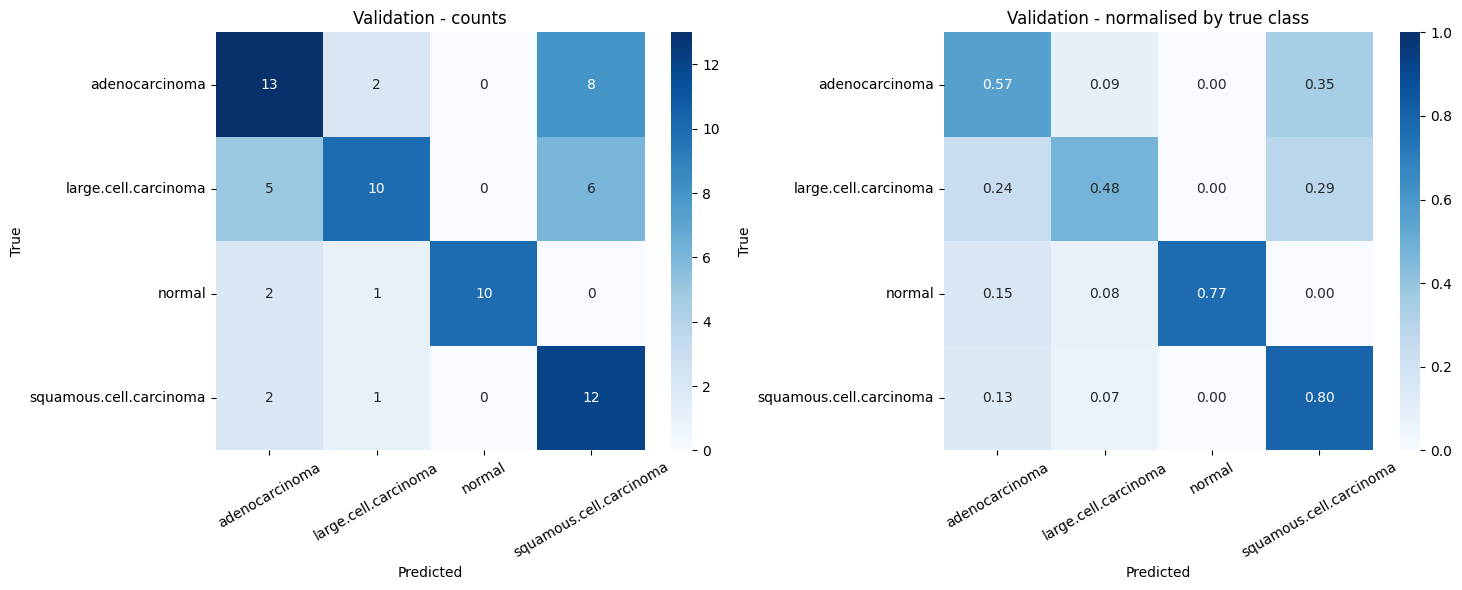

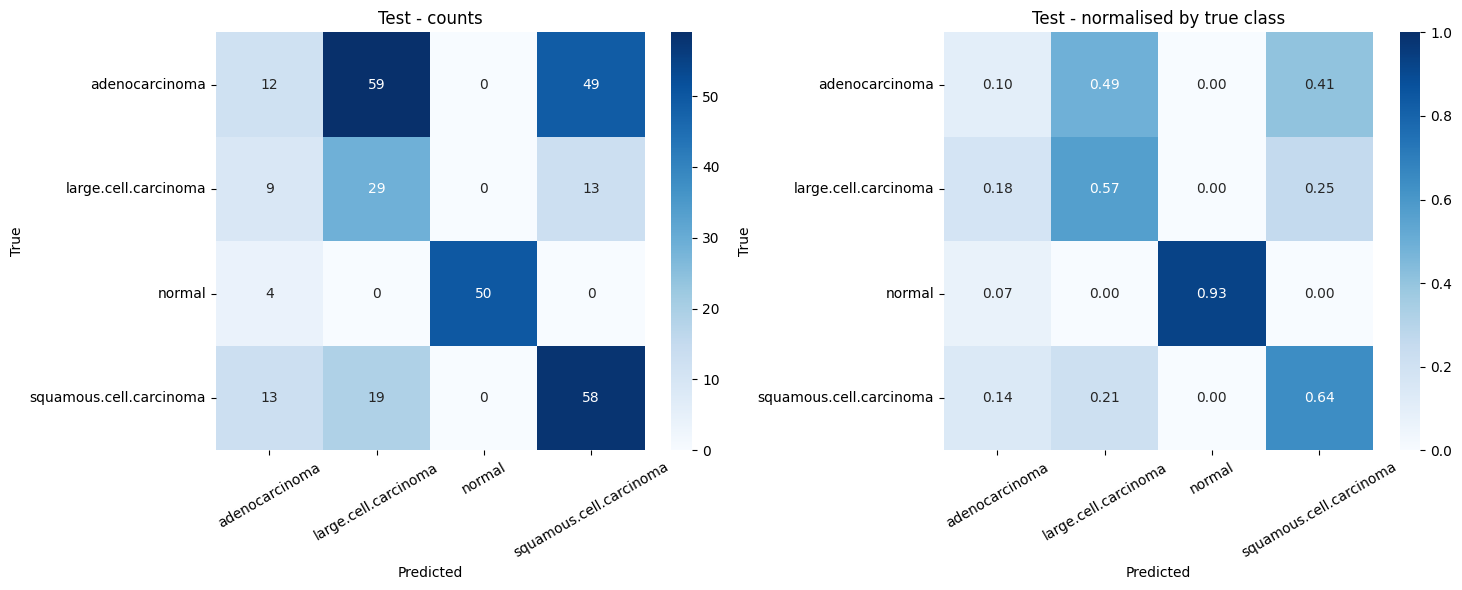

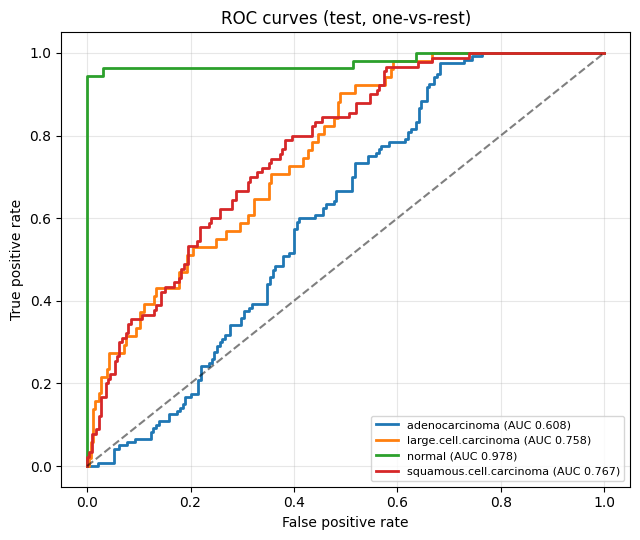

macro one-vs-rest AUC (test): 0.778


In [13]:
plot_confusion(results["val"][1], results["val"][2], CLASS_NAMES, "Validation", "confusion_val.png")
plot_confusion(ytest, ptest, CLASS_NAMES, "Test", "confusion_test.png")
test_auc = plot_roc(ytest, probtest, CLASS_NAMES)
print("macro one-vs-rest AUC (test):", round(test_auc, 4))

## 7. (Optional) Where do the global tokens look?

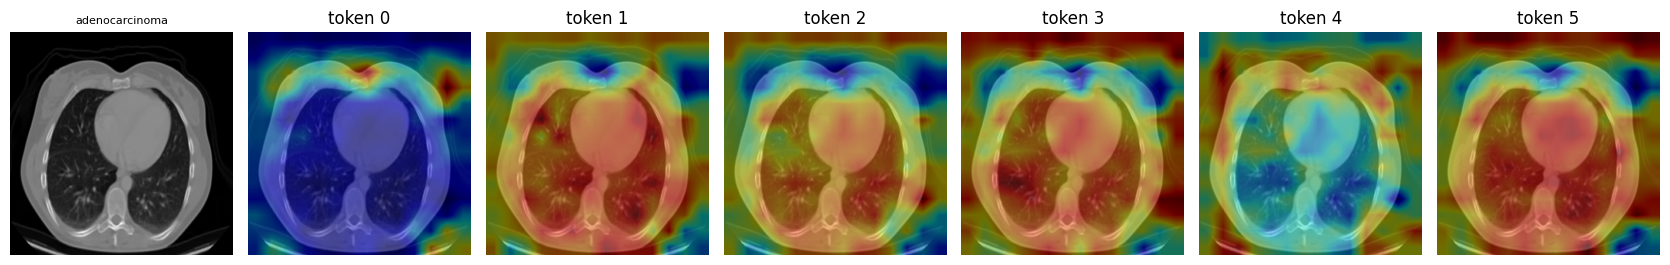

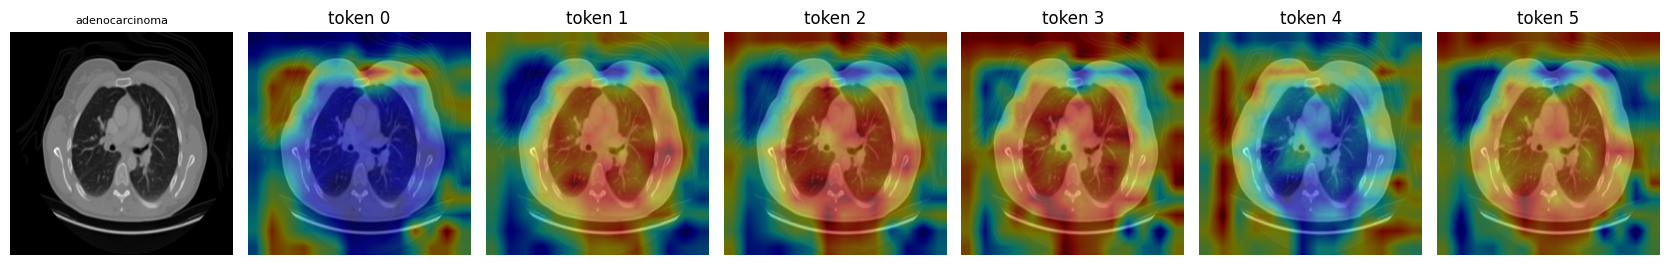

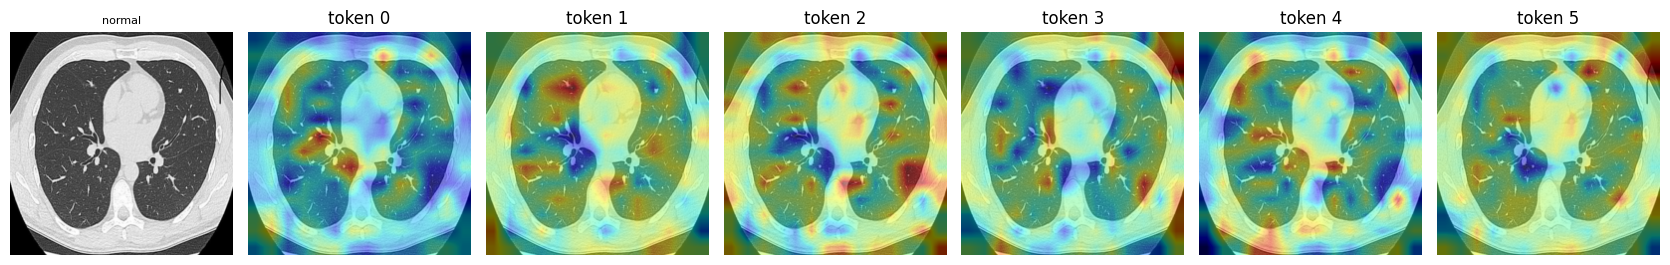

In [14]:
@torch.no_grad()
def show_token_attention(model, ds, idx, block=5):
    model.eval()
    x, y = ds[idx]
    model(x.unsqueeze(0).to(device))
    attn = model.blocks[block].f2m.last_attn[0].mean(0).cpu()       # (HW, M)
    hw = int(attn.shape[0] ** 0.5); M = attn.shape[1]
    fig, ax = plt.subplots(1, M + 1, figsize=(2.4 * (M + 1), 2.8))
    ax[0].imshow(x[0], cmap="gray"); ax[0].set_title(CLASS_NAMES[y], fontsize=8); ax[0].axis("off")
    for t in range(M):
        a = torch.nn.functional.interpolate(attn[:, t].reshape(1, 1, hw, hw), size=x.shape[-2:], mode="bilinear")[0, 0]
        ax[t + 1].imshow(x[0], cmap="gray"); ax[t + 1].imshow(a, cmap="jet", alpha=0.45)
        ax[t + 1].set_title(f"token {t}"); ax[t + 1].axis("off")
    plt.tight_layout(); plt.show()

for i in [0, len(test_ds) // 3, 2 * len(test_ds) // 3]:
    show_token_attention(model, test_ds, i)

## Notes
- Plain training by default. Set `USE_AUGMENTATION`, `USE_CLASS_WEIGHTS`, `LABEL_SMOOTHING` at the top to change this.
- Best weights: `best_mobileformer_ct.pt`. Figures are saved as PNGs in the working directory.
- With only ~600 training images, results vary noticeably between seeds; consider reporting mean +/- std over several seeds.
- Precision, recall and F1 are **macro** averages over the 4 classes; the classification report gives the per-class values.